# Step 5: Neural Rankers and the Dual-Horizon Attention Ranker (DHAR)

**BT4222 Final Project, Group 13, JDSearch**

Step 5 asks whether a neural model that reads the user's history sequence can beat LambdaMART on the same features. It trains the proposed **DHAR** (two attention towers, one over recent intent and one over past orders) together with four feature-based tower controls and a separate history-conditioned NCF-style baseline. The tower controls retain the engineered features to test the additional history representations. The CF baseline uses different inputs.

## How to read this notebook

The model and training functions are cut verbatim from `src/step5_neural.py`, so the notebook and the script cannot drift apart
(`tests/test_notebooks.py` checks it). Each cell is preceded by a short explanation of what it does and
why, and the table below links every section to the function that implements it and to the file it
produces, so any number in the report can be traced back to a cell.

* **Part A** rebuilds the step. It needs the inputs listed below.
* **Part B** reads the measured outputs of the corrected run (`artifacts/corrected`) and re-checks them.
  It needs no raw data, so it always runs and its outputs are saved in this copy of the notebook.

| Section | What it does | Code in `src/step5_neural.py` | Writes |
|---|---|---|---|
| A.1 | Variants and constants | `VARIANTS`, `NAMES`, `BRAND_BUCKETS` | - |
| A.2 | Device and seeding | `device`, `seed_everything` | - |
| A.3 | Preprocessing fitted on training data | `brand_bucket`, `fit_preprocessing` | `neural_preprocessing.json` |
| A.4 | Encode frames, build history sequences | `encode_frames` | - |
| A.5 | Pack slates into tensors | `pack` | - |
| A.6 | The models | `DHAR`, `HistoryCF` | - |
| A.7 | Listwise loss, batching, prediction | `listwise`, `forward_batch`, `predict_pack` | - |
| A.8 | Training loop with early stopping | `train_one` | `<variant>_seed<k>.pt`, `training_<variant>_seed<k>.json` |
| A.9 | Run every variant | `main()` | `results_neural.json`, `test_pred_neural.parquet`, `horizon_coverage.json` |
| B.1 | Neural results | - | - |
| B.2 | Recompute from saved predictions | - | - |
| B.3 | Training curves and sequence coverage | - | - |

**Inputs.** `features.parquet`, `history.parquet`, `meta_subset.parquet` (Steps 2 and 3).

**Outputs.** One checkpoint and training log per variant, `results_neural.json`, `test_pred_neural.parquet` (test scores of all variants).

## The six variants

All variants are trained with the same data, packing, loss, optimiser, early stopping and seed. They differ
in representation and, for the CF baseline, information available.

| Key | Name | What it sees |
|---|---|---|
| `mlp` | MLP (no towers) | candidate category + brand embeddings and the 26 features; **no history sequence** |
| `pooled` | Pooled history | as `mlp` plus one mean over concatenated short/order positions, repeated in both context slots |
| `short_only` | Short only | as `mlp` plus an attention tower over the recent-intent sequence |
| `order_only` | Order only | as `mlp` plus an attention tower over the order sequence |
| `dual` | **DHAR** | as `mlp` plus **both** towers: the candidate's category embedding attends separately over recent intent and over past orders |
| `history_cf` | History-conditioned CF | an NCF-style model of item embeddings with the user represented by the mean of up to 40 known history items sampled evenly across the complete history (no engineered features) |

The key comparison is `dual` against `mlp`: both receive the same engineered history features, so the
difference isolates what attention adds.

**Training details.** Listwise loss: a softmax over each slate trained against the normalised gains
`[0, 1, 3, 7]` (slates without a positive are skipped). Training slates are cut to 64 candidates (all
positives plus a seeded sample of negatives); validation and test use the **full** slates (up to 200).
Adam, learning rate 0.002, weight decay 1e-6, batch 128, at most 20 epochs, stop after 3 epochs without validation gain and
keep the best checkpoint. Embedding size 32; feature-based head 128-64-1 with dropout 0.2. CF uses a separate 64-32 MLP and a linear fusion head. Sequences keep up to 20
category ids, evenly spaced over the whole horizon (40 items for `history_cf`); events whose metadata is
unknown are dropped before sampling.

## 0. Environment setup

The first cell finds the project and puts `src/` on `sys.path`, so `config`, `data_utils`
and `eval_utils` can be imported exactly as the scripts do.

* **In Colab** it clones the repository (branch set in `BRANCH`). Set `MOUNT_DRIVE = True` if the
  raw files live on Google Drive: raw paths and the output folder then point to Drive, so the
  outputs of one step survive until the next notebook.
* **Locally** it looks for `Final Project/` next to the notebook.
* All paths come from environment variables read by `src/config.py`:
  `JD_USER_TXT`, `JD_PRODUCT_TXT` (raw files), `JD_RUN_DIR` (where outputs are written, default
  `artifacts/corrected`), `JD_SEED` (default 42).

In [1]:
# Optional: install dependencies in a fresh environment (Colab already has most of them)
# !pip -q install numpy pandas pyarrow scipy scikit-learn lightgbm joblib matplotlib torch

import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/steffanylars/nus-web-mining-business-insights.git"
BRANCH = "steff-coldstart-diversity"   # change to the team's final branch before submission
MOUNT_DRIVE = False                    # Colab only: True keeps raw data and outputs on Google Drive
DRIVE_DIR = "/content/drive/MyDrive/JDsearch"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if MOUNT_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        os.environ.setdefault("JD_USER_TXT", f"{DRIVE_DIR}/user_behavior_data.txt")
        os.environ.setdefault("JD_PRODUCT_TXT", f"{DRIVE_DIR}/product_meta_data.txt")
        os.environ.setdefault("JD_RUN_DIR", f"{DRIVE_DIR}/runs/corrected")
    repo = Path("/content/nus-web-mining-business-insights")
    if not (repo / ".git").exists():
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, str(repo)], check=True)
    PROJECT_ROOT = repo / "Final Project"
else:
    here = Path.cwd()
    options = [here, here.parent, here / "Final Project", here.parent / "Final Project"]
    PROJECT_ROOT = next((p for p in options if (p / "src" / "config.py").exists()), None)
    assert PROJECT_ROOT is not None, "open this notebook from Final Project/ or Final Project/notebooks/"

SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
print("in Colab    :", IN_COLAB)
print("project root:", PROJECT_ROOT)
print("run dir     :", os.environ.get("JD_RUN_DIR", "<default: artifacts/corrected>"))

in Colab    : False
project root: Final Project
run dir     : <default: artifacts/corrected>


## 1. Imports and shared helpers

PyTorch builds the models. `short_mask` and `select_sequence` (in `data_utils`) define the short
horizon and the even sampling of a long history; `evaluate` is the shared scorer.

In [2]:
import copy, hashlib, json, math, random, time
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
from IPython.display import display

from config import (OUT, RES, SEED, HISTORY_LENGTH, EPOCHS, BATCH_SIZE, THREADS,
                    feature_columns, prepare, save_json)
from data_utils import short_mask, select_sequence
from eval_utils import evaluate

%matplotlib inline
prepare()
print("history length:", HISTORY_LENGTH, "| max epochs:", EPOCHS, "| batch size:", BATCH_SIZE)

history length: 20 | max epochs: 20 | batch size: 128


### 1.1 What can run here? (the `RUN_STEP` switch)

Part A rebuilds this step and Part B reads the measured outputs, so the switch below decides whether
Part A runs.

* Part A runs only if its **inputs exist**, and it will not overwrite the committed evidence in
  `artifacts/corrected` unless you explicitly allow it (`ALLOW_OVERWRITE`). In Colab the clone is
  disposable, so overwriting is allowed by default; locally, point `JD_RUN_DIR` at a new folder.
* If Part A is skipped, nothing fails: **Part B always runs** and shows the saved results.

In [3]:
COMMITTED = (PROJECT_ROOT / "artifacts" / "corrected").resolve()
ALLOW_OVERWRITE = IN_COLAB      # a Colab clone is disposable; locally keep the committed evidence safe
HAS_INPUTS = all((OUT / f"{n}.parquet").exists() for n in ["features", "history", "meta_subset"])
RUN_STEP = HAS_INPUTS and (RES.resolve() != COMMITTED or ALLOW_OVERWRITE)

print("inputs found    :", HAS_INPUTS)
print("outputs go to   :", RES)
print("RUN_STEP        :", RUN_STEP)
if not RUN_STEP:
    why = ("required inputs not found: features, history, meta_subset parquet files (run Steps 2 and 3 first)" if not HAS_INPUTS else
           "outputs would overwrite artifacts/corrected; set JD_RUN_DIR to a new folder or ALLOW_OVERWRITE = True")
    print("Part A is skipped here (" + why + ").")
    print("Part B below shows the measured outputs saved in", RES)

inputs found    : False
outputs go to   : Final Project/artifacts/corrected
RUN_STEP        : False
Part A is skipped here (required inputs not found: features, history, meta_subset parquet files (run Steps 2 and 3 first)).
Part B below shows the measured outputs saved in Final Project/artifacts/corrected


# Part A: Train the neural rankers

### A.1 Variants and constants

In [4]:
VARIANTS = ['mlp','pooled','short_only','order_only','dual','history_cf']
NAMES = {'mlp':'MLP(no towers)','pooled':'Pooled history','short_only':'Short only',
         'order_only':'Order only','dual':'DHAR(ours)','history_cf':'History-conditioned CF'}
BRAND_BUCKETS = 20000

### A.2 Device and seeding

The device is picked automatically (CUDA, then Apple MPS, then CPU). `seed_everything` fixes Python,
NumPy and PyTorch so a variant can be rerun.

In [5]:
def device():
    return torch.device('cuda' if torch.cuda.is_available() else
                        'mps' if torch.backends.mps.is_available() else 'cpu')

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

### A.3 Preprocessing fitted on training data only

`fit_preprocessing` computes everything the models need to turn raw columns into inputs: mean and
standard deviation of each feature (training rows only), the vocabulary of level-3 categories and of
items seen in training, and the hashing of brand ids into 20,000 buckets (`brand_bucket`, a stable hash,
so the same brand always gets the same bucket in any run). Validation and test never influence it.

In [6]:
def brand_bucket(value):
    if value is None or pd.isna(value) or str(value).strip() in {'','-1'}:
        return 0
    digest=hashlib.blake2b(str(value).encode(),digest_size=8).digest()
    return int.from_bytes(digest,'little')%(BRAND_BUCKETS-1)+1

def fit_preprocessing(feat,hist,meta,length):
    cols=feature_columns(feat); train=feat.split.eq('train')
    train_ids=set(feat.loc[train,'session_id'])
    train_hist=hist[hist.session_id.isin(train_ids)]
    train_wids=set(feat.loc[train,'cand_wid'])|set(train_hist.wid)
    tm=meta[meta.wid.isin(train_wids)]
    categories=sorted(c for c in tm.cate_id_3.dropna().unique() if str(c).strip())
    mu=feat.loc[train,cols].mean()
    sd=feat.loc[train,cols].std().fillna(1).replace(0,1)
    return dict(schema_version=2,feature_columns=cols,mean=mu.tolist(),std=sd.tolist(),
        category_ids={str(c):i+1 for i,c in enumerate(categories)},
        item_ids={w:i+1 for i,w in enumerate(sorted(train_wids))},
        history_length=length,cf_history_length=2*length,brand_buckets=BRAND_BUCKETS,
        brand_hash='blake2b UTF-8, 8 bytes little-endian; modulo 19999 + 1',
        sequence_policy='evenly spaced positions over each complete chronological horizon',
        short_policy='CLICK <=7d or CART <=90d',order_policy='all preceding ORD events')

### A.4 Encode features and build the history sequences

`encode_frames` standardises the features, maps each candidate to category, brand and item ids, and
builds three sequences per session from the **complete** history: the **short** sequence (clicks of the
last 7 days and carts of the last 90 days), the **order** sequence (all orders) and the **cf** sequence
(every event, for the collaborative-filtering variant). Unknown ids are removed first, then up to
`length` positions are sampled evenly across the horizon. The returned `coverage` table reports how
many events were eligible, unknown and kept.

In [7]:
def encode_frames(feat,hist,meta,prep):
    frame=feat.copy()
    cols=prep['feature_columns']
    frame[cols]=((frame[cols]-np.array(prep['mean']))/np.array(prep['std'])).astype('float32')
    if not np.isfinite(frame[cols].to_numpy()).all():
        raise ValueError('Nonfinite neural features')
    maps=meta.set_index('wid')
    cat=maps.cate_id_3.to_dict(); brand=maps.brand_id.to_dict()
    frame['_c3']=frame.cand_wid.map(cat).map(prep['category_ids']).fillna(0).astype(int)
    frame['_bi']=frame.cand_wid.map(brand).map(brand_bucket).astype(int)
    frame['_ii']=frame.cand_wid.map(prep['item_ids']).fillna(0).astype(int)
    h=hist.sort_values(['session_id','pos']).copy()
    h['_c3']=h.wid.map(cat).map(prep['category_ids']).fillna(0).astype(int)
    h['_ii']=h.wid.map(prep['item_ids']).fillna(0).astype(int)
    sequences={}; coverage={}
    for name,subset,col,length in [
        ('short',h[short_mask(h)],'_c3',prep['history_length']),
        ('order',h[h.type.eq('ORD')],'_c3',prep['history_length']),
        ('cf',h,'_ii',prep['cf_history_length'])]:
        seq={}; eligible=retained=unknown=0
        for sid,g in subset.groupby('session_id',sort=False):
            values=g[col].to_numpy()
            eligible+=len(values); unknown+=int((values==0).sum())
            # Unknown metadata/items are excluded before position sampling.
            selected=select_sequence(values[values>0],length)
            seq[sid]=selected; retained+=len(selected)
        sequences[name]=seq
        coverage[name]={'eligible_events':eligible,'unknown_events':unknown,'selected_events':retained,
                        'users_with_known_sequence':sum(bool(len(v)) for v in seq.values())}
    return frame,sequences,coverage

### A.5 Pack the slates into tensors

`pack` stacks each split into fixed-width arrays (features, ids, labels, mask, sequences). Candidates are
put in a canonical order so file order cannot influence sampling or rounding. Training slates wider than
the width are reduced to all positives plus a seeded sample of negatives; evaluation slates must fit
entirely or the function raises an error, so no candidate is ever silently dropped from evaluation.

In [8]:
def pack(frame,sequences,prep,split,width=200,seed=SEED):
    cols=prep['feature_columns']; groups=frame[frame.split.eq(split)].groupby('session_id',sort=True)
    n=len(groups); nf=len(cols); L=prep['history_length']; H=prep['cf_history_length']
    arrays=dict(num=np.zeros((n,width,nf),dtype=np.float32),
        c3=np.zeros((n,width),dtype=np.int64),bi=np.zeros((n,width),dtype=np.int64),
        ii=np.zeros((n,width),dtype=np.int64),lab=np.zeros((n,width),dtype=np.int64),
        mask=np.zeros((n,width),dtype=bool),ridx=np.full((n,width),-1,dtype=np.int64),
        short=np.zeros((n,L),dtype=np.int64),order=np.zeros((n,L),dtype=np.int64),
        cf=np.zeros((n,H),dtype=np.int64))
    for row,(sid,g) in enumerate(groups):
        # Canonical order prevents source positions influencing sampling/roundoff.
        g=g.sort_values('cand_wid')
        if len(g)>width:
            if split!='train':
                raise ValueError('Evaluation must use every supplied candidate')
            rng=np.random.default_rng(np.random.SeedSequence([seed,int(sid)]))
            pos=np.flatnonzero(g.label.to_numpy()>0); neg=np.flatnonzero(g.label.to_numpy()==0)
            if len(pos)>width:
                raise ValueError('Training width is smaller than number of positives')
            selected=np.r_[pos,rng.choice(neg,width-len(pos),replace=False)]
            g=g.iloc[selected].sort_values('cand_wid')
        m=len(g)
        arrays['num'][row,:m]=g[cols].to_numpy(dtype=np.float32)
        for key,col in [('c3','_c3'),('bi','_bi'),('ii','_ii'),('lab','label')]:
            arrays[key][row,:m]=g[col].to_numpy()
        arrays['mask'][row,:m]=True; arrays['ridx'][row,:m]=g.index.to_numpy()
        for key in ['short','order','cf']:
            v=sequences[key].get(sid,[])
            arrays[key][row,:len(v)]=v
    return {k:torch.from_numpy(v) for k,v in arrays.items()}

### A.6 The models: presentation explanation

**Question:** does separating recent intent and order history add useful information beyond the same engineered history features?

| Input | DHAR and feature-based controls | History-conditioned NCF-style baseline (`HistoryCF`) |
|---|---|---|
| Candidate | Level 3 category embedding (32), hashed brand embedding (32) | Item-ID embedding (32) |
| Current query | Through the 26 engineered features, including query-product matching; no separate query-text encoder | Not used |
| User history | Short: CLICK <=7 days or CART <=90 days; order: all preceding ORD events | All preceding event types, represented by item IDs |
| Sequence construction | Up to 20 known-category positions per horizon, sampled evenly | Up to 40 known-item positions, sampled evenly |
| Numeric features | 26 standardised inputs, including engineered historical preference features | Not used |
| Unknown / empty inputs | Unknown categories use index 0; unknown history positions are removed; empty context is zero | Unseen items use index 0; unknown history items are removed; empty history mean is zero |

**DHAR architecture.** Candidate and history categories share an embedding table. Each tower projects the candidate category embedding into a query, applies scaled dot-product attention to its history category embeddings, masks padding, and returns a 32-dimensional weighted context. Candidate brand is fused later; it does not query attention. Concatenating category (32), brand (32), short context (32), order context (32), and numeric features (26) yields **154 inputs**, followed by **128 -> 64 -> 1**, with ReLU and dropout 0.2 after each hidden layer. The final output is an unnormalised relevance score.

**NCF-style architecture.** This implementation adapts GMF + MLP using a history-derived user vector rather than a learned user-ID embedding. One shared item table embeds the candidate and historical items. The masked mean of known history embeddings gives a user vector (32). The GMF branch forms `user * candidate` (32); the MLP branch maps their concatenation **64 -> 64 -> 32** with ReLU. Concatenating the two branches gives 64 inputs to a linear **64 -> 1** scorer. There is no dropout in this CF model. Call it **history-conditioned NCF-style CF**, rather than an exact reproduction of standard NCF.

**Controls and limits.** `mlp` zeros both contexts but keeps the 26 features, including history features; it is not history-free. `short_only` and `order_only` zero the unused context. `pooled` takes one mean over concatenated horizon positions and repeats it in both slots. There is no positional encoding or explicit recency decay in attention: horizon membership uses action/time rules, while attention weights are learned. These models do not implement every idea in the interim proposal (for example, a learned embedding for each of click/cart/follow/purchase). CF has different inputs and is a separate baseline, not a matched tower ablation.


In [9]:
class DHAR(nn.Module):
    def __init__(self,nc3,nb,nf,variant='dual',d=32,**unused):
        super().__init__(); self.variant=variant
        self.ec3=nn.Embedding(nc3,d,padding_idx=0); self.eb=nn.Embedding(nb,d,padding_idx=0)
        self.ps=nn.Linear(d,d); self.pl=nn.Linear(d,d)
        self.head=nn.Sequential(nn.Linear(4*d+nf,128),nn.ReLU(),nn.Dropout(.2),
            nn.Linear(128,64),nn.ReLU(),nn.Dropout(.2),nn.Linear(64,1))
    def attend(self,q,seq,projection):
        emb=self.ec3(seq); mask=seq>0
        score=torch.einsum('bsd,bld->bsl',projection(q),emb)/math.sqrt(emb.size(-1))
        score=score.masked_fill(~mask[:,None,:],-1e9)
        weight=torch.softmax(score,dim=-1)*mask[:,None,:]
        weight=weight/weight.sum(-1,keepdim=True).clamp_min(1e-9)
        return torch.einsum('bsl,bld->bsd',weight,emb)
    def forward(self,num,c3,bi,ii,short,order,cf):
        qc=self.ec3(c3); qb=self.eb(bi); sc=torch.zeros_like(qc); lc=torch.zeros_like(qc)
        if self.variant in {'dual','short_only'}:
            sc=self.attend(qc,short,self.ps)
        if self.variant in {'dual','order_only'}:
            lc=self.attend(qc,order,self.pl)
        if self.variant=='pooled':
            both=torch.cat([short,order],dim=1); mask=both>0
            pool=(self.ec3(both)*mask[:,:,None]).sum(1)/mask.sum(1,keepdim=True).clamp_min(1)
            sc=pool[:,None,:].expand_as(qc); lc=sc
        return self.head(torch.cat([qc,qb,sc,lc,num],dim=-1)).squeeze(-1)

class HistoryCF(nn.Module):
    """GMF+MLP with a mean history encoder instead of per-session embeddings."""
    def __init__(self,ni,d=32,**unused):
        super().__init__()
        self.item=nn.Embedding(ni,d,padding_idx=0)
        self.mlp=nn.Sequential(nn.Linear(2*d,64),nn.ReLU(),nn.Linear(64,32),nn.ReLU())
        self.out=nn.Linear(d+32,1)
    def forward(self,num,c3,bi,ii,short,order,cf):
        mask=cf>0
        user=(self.item(cf)*mask[:,:,None]).sum(1)/mask.sum(1,keepdim=True).clamp_min(1)
        candidate=self.item(ii); user=user[:,None,:].expand_as(candidate)
        return self.out(torch.cat([user*candidate,self.mlp(torch.cat([user,candidate],-1))],-1)).squeeze(-1)

### A.6.1 Neural-model diagrams

The diagrams below are embedded in this notebook and travel with the file.

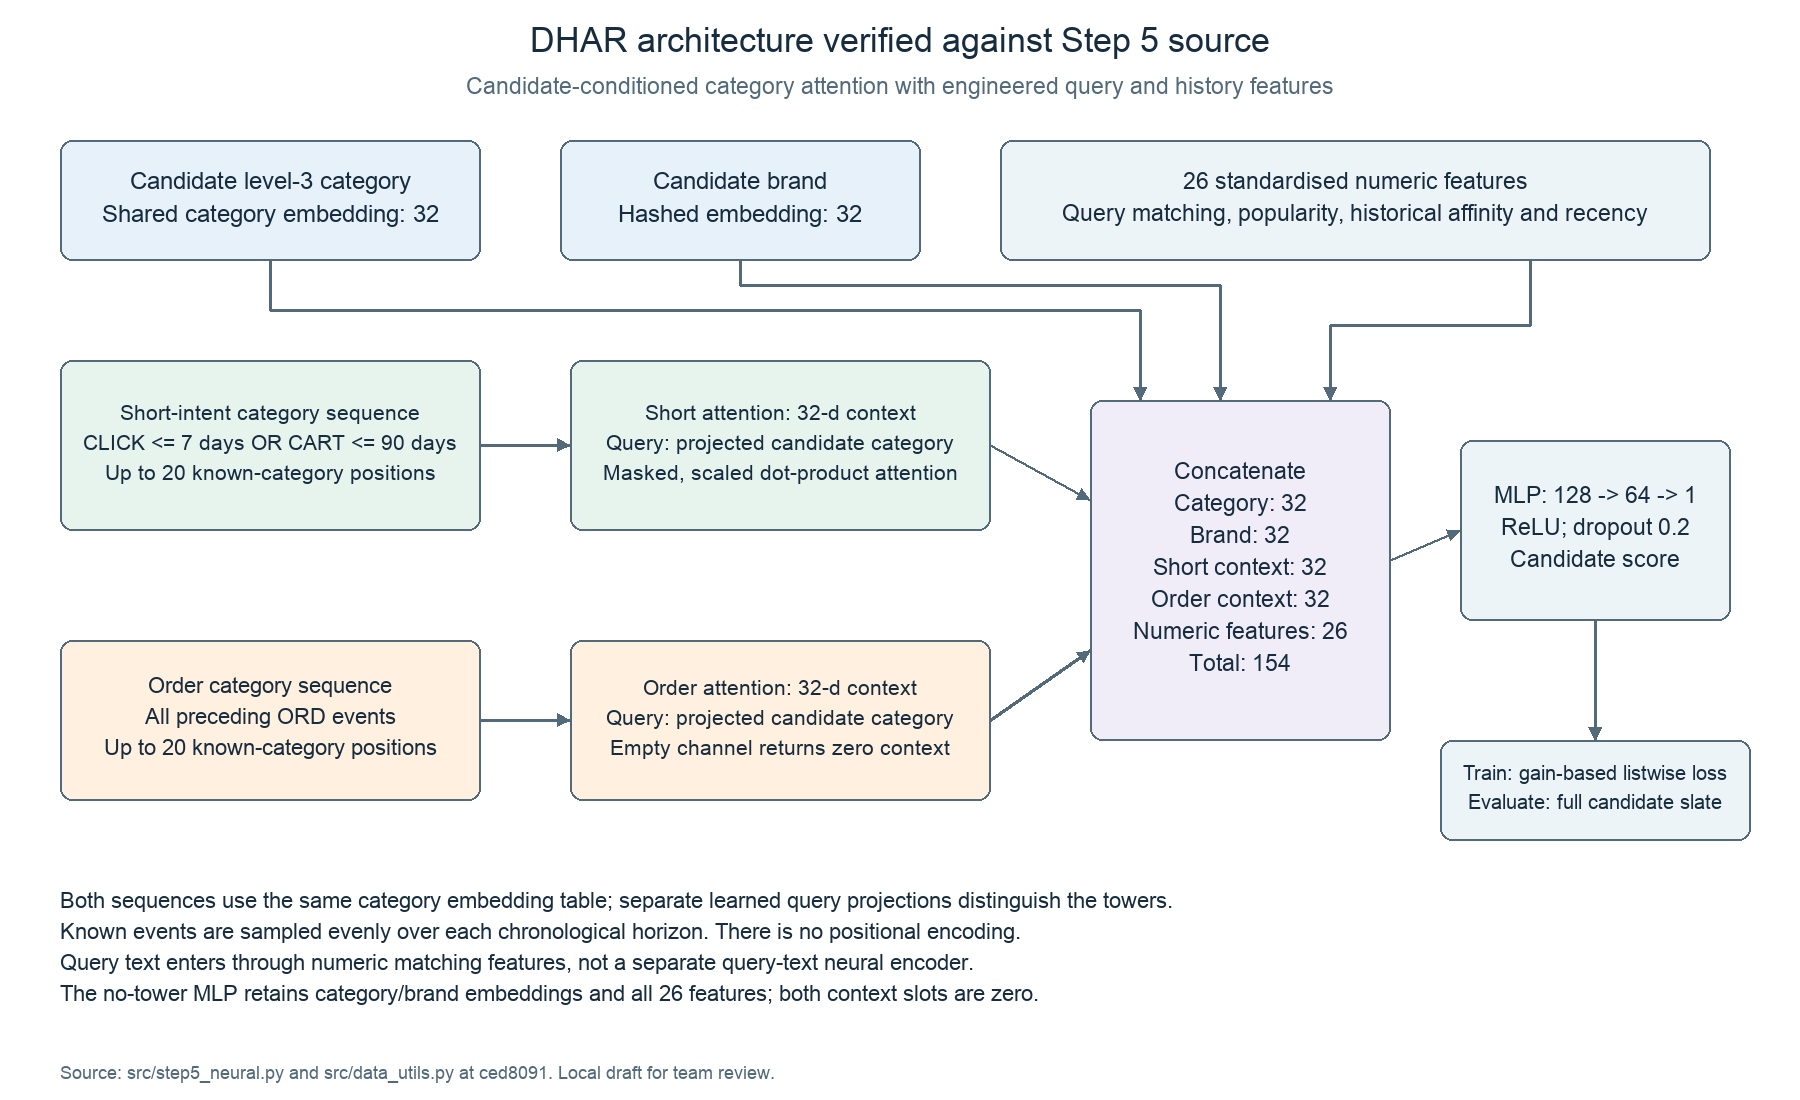

**DHAR:** metadata and numeric query/history features are fused with separate short-intent and order attention contexts. The category embedding supplies each attention query; the brand joins the prediction head.

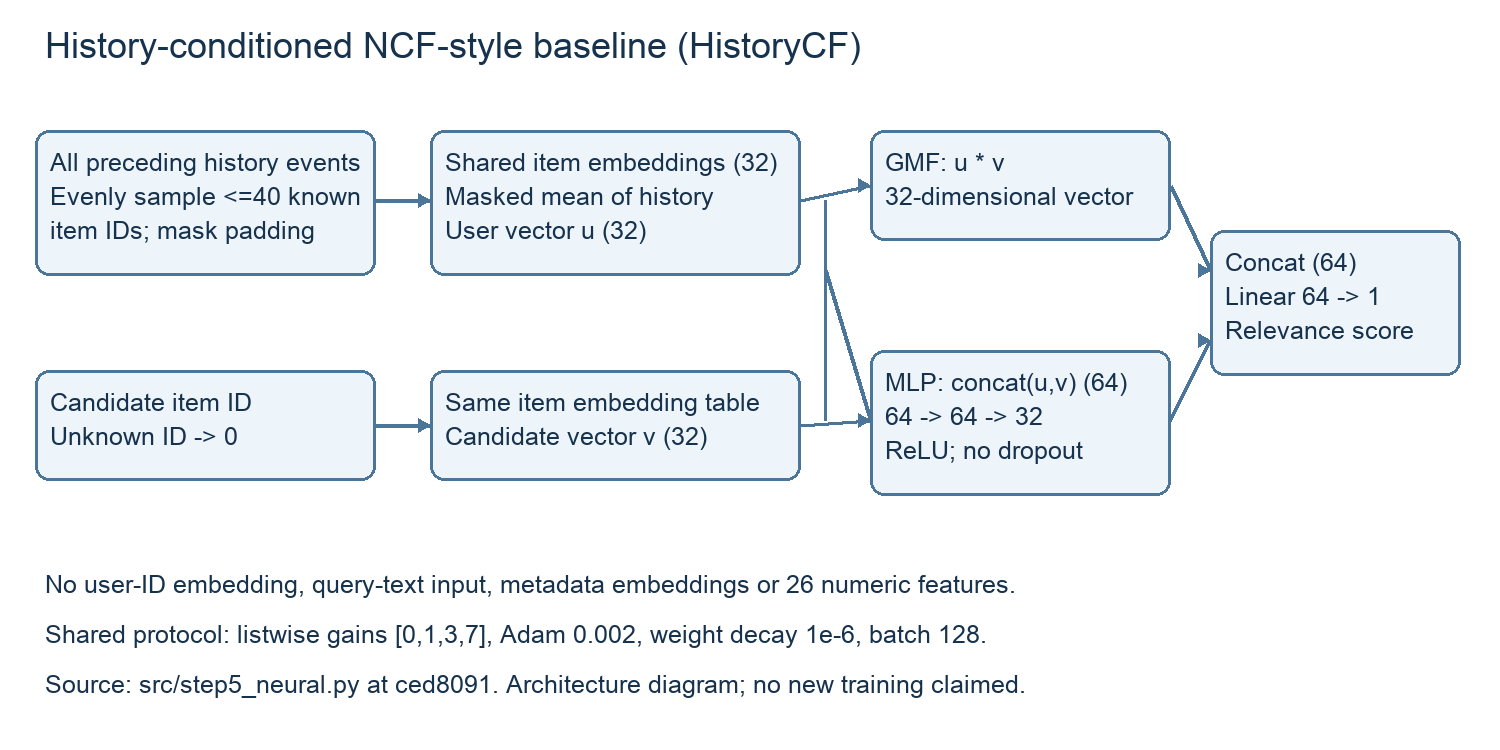

**NCF-style CF:** the user vector comes from mean item-history embeddings rather than a user-ID lookup. It combines a GMF product and an MLP, without the DHAR metadata/numeric inputs.


### A.7 Loss, batching and prediction

* `listwise` turns each slate's gains into a target distribution and minimises the cross-entropy to the
  softmax of the scores, so the model learns the **order** within a slate, with purchases weighing more.
* `forward_batch` moves one batch to the device and calls the model.
* `predict_pack` scores a whole split and writes each score back to the row it came from (`ridx`), which
  keeps predictions aligned with the original frame.

In [10]:
def listwise(scores,lab,mask):
    gain=torch.tensor([0.,1.,3.,7.],device=scores.device)[lab]*mask
    target=gain/gain.sum(1,keepdim=True).clamp_min(1e-9)
    loss=-(target*F.log_softmax(scores.masked_fill(~mask,-1e9),dim=1)).sum(1)
    positive=gain.sum(1)>0
    return loss[positive].mean() if positive.any() else scores.sum()*0

def forward_batch(model,pk,indices,dev):
    return model(*[pk[k][indices].to(dev) for k in ['num','c3','bi','ii','short','order','cf']])

def predict_pack(model,pk,n_rows,dev):
    model.eval(); scores=np.zeros(n_rows,dtype=np.float32)
    with torch.no_grad():
        for a in range(0,len(pk['num']),BATCH_SIZE):
            sl=slice(a,a+BATCH_SIZE)
            value=forward_batch(model,pk,sl,dev).cpu().numpy()
            ids=pk['ridx'][sl].numpy(); mask=pk['mask'][sl].numpy()
            scores[ids[mask]]=value[mask]
    return scores

### A.8 Training one variant

For each epoch: shuffle the training slates, minimise the listwise loss, score the validation slates and
compute NDCG@10. The best validation checkpoint is kept (patience 3), saved as `<variant>_seed<k>.pt`,
and the loss and validation curve are logged in `training_<variant>_seed<k>.json`.

In [11]:
def train_one(variant,prep,frame,packs,seed,dev):
    seed_everything(seed)
    spec=dict(nc3=len(prep['category_ids'])+1,nb=prep['brand_buckets'],
              nf=len(prep['feature_columns']),ni=len(prep['item_ids'])+1,variant=variant)
    model=(HistoryCF(**spec) if variant=='history_cf' else DHAR(**spec)).to(dev)
    optimizer=torch.optim.Adam(model.parameters(),lr=.002,weight_decay=1e-6)
    best=-1.; state=None; bad=0; log=[]; start=time.time()
    val=frame[frame.split.eq('val')].copy()
    tr=packs['train']
    for epoch in range(1,EPOCHS+1):
        model.train(); perm=np.random.permutation(len(tr['num'])); total=0.; batches=0
        for a in range(0,len(perm),BATCH_SIZE):
            ix=perm[a:a+BATCH_SIZE]
            score=forward_batch(model,tr,ix,dev)
            loss=listwise(score,tr['lab'][ix].to(dev),tr['mask'][ix].to(dev))
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            total+=float(loss.detach()); batches+=1
        scores=predict_pack(model,packs['val'],len(frame),dev)
        val['score']=scores[val.index.to_numpy()]
        metrics,n=evaluate(val,'score'); ndcg=metrics['NDCG@10']
        log.append(dict(epoch=epoch,loss=total/max(batches,1),val_ndcg10=ndcg))
        print(f'{variant} seed={seed} epoch={epoch} val={ndcg:.5f} elapsed={time.time()-start:.0f}s',flush=True)
        if ndcg>best:
            best=ndcg; state=copy.deepcopy({k:v.detach().cpu() for k,v in model.state_dict().items()}); bad=0
        else:
            bad+=1
            if bad>=3: break
    model.load_state_dict(state)
    name=f'{variant}_seed{seed}'
    torch.save({'state_dict':state,'spec':spec,'schema_version':2},OUT/f'{name}.pt')
    save_json(RES/f'training_{name}.json',dict(seed=seed,variant=variant,epochs=log,
        best_validation_ndcg10=best,training_slate_width=packs['train']['mask'].shape[1],
        evaluation_slate_width=200,batch_size=BATCH_SIZE,device=str(dev)))
    return model

### A.8.1 Shared training setup for the presentation

| Setting | Implemented / saved experiment |
|---|---|
| Data split | 20,000 sampled user records: 14,000 training, 3,000 validation, 3,000 test; fixed seed 42 |
| Preprocessing | Numeric mean/std and category/item vocabularies fitted using training records only; deterministic brand hashing into 20,000 buckets |
| Training candidates | At most 64 per query, keeping every positive and a seeded negative sample |
| Validation / test candidates | Complete supplied slates, up to 200; no evaluation negative sampling |
| Objective | Listwise cross-entropy: normalised gains [0, 1, 3, 7] against softmax candidate scores; all-negative slates contribute zero loss |
| Optimiser | Adam, learning rate 0.002, weight decay 1e-6 |
| Batch / budget | 128 query slates; maximum 20 epochs |
| Model selection | Best validation NDCG@10; early-stopping patience 3 |
| Existing saved run | CPU, seed 42; DHAR best epoch 2 / 5 epochs logged; CF best epoch 15 / 18 logged |
| Evaluation | NDCG@10 uses exponential gains; MRR@200, P@1 and HR@10 use binary relevance (label >0) |
| Evaluable test queries | 2,965 of 3,000; 35 all-negative query slates excluded by the shared evaluator |

The gains are fixed **target relevance gains**, not manually assigned weights for historical click/cart/follow/purchase events. Historical actions enter DHAR through the engineered features and horizon rules. The attention weights are learned over history categories.

**Reproducing a run:** Part A needs Step 2/3 parquet inputs and Torch. Part B reads committed results; it does not retrain. Check `BRANCH` in setup against the team branch before cloning in Colab (the existing setup currently names `steff-coldstart-diversity`). Use a separate output directory for a new experiment.


### A.9 Run every variant

`RUN_VARIANTS` can be shortened for a quick trial (for example `["mlp", "dual"]`). The three cells
below are the body of `main()`: fit the preprocessing, encode and pack once (so **every variant sees the
same negatives and the same evaluation slates**), then train and evaluate each variant on test and
validation, saving results after every variant so completed outputs can be inspected. This loop does not automatically resume or skip completed variants.

In [12]:
RUN_VARIANTS = VARIANTS      # e.g. ["mlp", "dual"] for a quick trial
RUN_SEEDS = [SEED]

In [13]:
if RUN_STEP:
    prepare(); torch.set_num_threads(THREADS); dev=device()
    print('device',dev,flush=True)

In [14]:
if RUN_STEP:
    feat=pd.read_parquet(OUT/'features.parquet')
    hist=pd.read_parquet(OUT/'history.parquet')
    meta=pd.read_parquet(OUT/'meta_subset.parquet')
    prep=fit_preprocessing(feat,hist,meta,HISTORY_LENGTH)
    save_json(OUT/'neural_preprocessing.json',prep)

In [15]:
if RUN_STEP:
    frame,sequences,coverage=encode_frames(feat,hist,meta,prep)
    save_json(RES/'horizon_coverage.json',coverage)
    # Same fixed negative sample and complete eval slates for every architecture.
    packs={s:pack(frame,sequences,prep,s,64 if s=='train' else 200)
           for s in ['train','val','test']}

In [16]:
if RUN_STEP:
    results={}; predictions=feat.loc[feat.split.eq('test'),['session_id','cand_wid','label']].copy()
    for seed in RUN_SEEDS:
        for variant in RUN_VARIANTS:
            model=train_one(variant,prep,frame,packs,seed,dev)
            key=NAMES[variant] if len(RUN_SEEDS)==1 else f'{NAMES[variant]} seed{seed}'
            test_scores=predict_pack(model,packs['test'],len(frame),dev)
            col=f'{variant}_score' if len(RUN_SEEDS)==1 else f'{variant}_seed{seed}_score'
            predictions[col]=test_scores[predictions.index.to_numpy()]
            m,n=evaluate(predictions,col); results[key]=m
            print('TEST',key,m,flush=True)
            val=frame[frame.split.eq('val')].copy()
            score=predict_pack(model,packs['val'],len(frame),dev)
            val['score']=score[val.index.to_numpy()]
            results[key+'_val']=evaluate(val,'score')[0]
            # Incremental saves allow a long CPU run to be resumed/reviewed.
            predictions.to_parquet(OUT/'test_pred_neural.parquet',index=False)
            save_json(RES/'results_neural.json',results)
            del model
    print('Neural variants complete',flush=True)

# Part B: Measured outputs of the corrected run

### B.1 Neural results

Test metrics on the same 2,965 positive test queries as Step 4, plus the validation NDCG@10 used for
model selection.

In [17]:
res = json.loads((RES / "results_neural.json").read_text(encoding="utf-8"))
test_rows = {k: v for k, v in res.items() if not k.endswith("_val")}
val_rows = {k[:-4]: v for k, v in res.items() if k.endswith("_val")}
table = pd.DataFrame(test_rows).T[["NDCG@10", "MRR@200", "P@1", "HR@10"]]
table.insert(0, "val NDCG@10", pd.Series({k: v["NDCG@10"] for k, v in val_rows.items()}))
display(table.round(4))

,val NDCG@10,NDCG@10,MRR@200,P@1,HR@10
MLP(no towers),0.3676,0.3725,0.3840,0.2519,0.6580
Pooled history,0.3679,0.3738,0.3844,0.2513,0.6631
Short only,0.3692,0.3713,0.3826,0.2503,0.6583
Order only,0.3678,0.3731,0.3825,0.2496,0.6621
DHAR(ours),0.3689,0.3713,0.3831,0.2499,0.6583
History-conditioned CF,0.2712,0.2694,0.2711,0.1403,0.5474


**Reading for the presentation.** Among the five feature-based variants, test NDCG@10 ranges from 0.3713 to 0.3738. DHAR reaches **0.3713**, versus **0.3725** for the same-feature no-tower MLP and **0.2694** for history-conditioned CF. All five feature-based variants exceed the saved LambdaMART result (0.3630), but the CF comparison also changes the available information.

The paired DHAR-minus-MLP NDCG@10 difference is **-0.00116**, with a query-bootstrap 95% interval **[-0.00336, +0.00109]** (2,000 resamples, seed 42). The interval includes zero: this run does not demonstrate an incremental attention benefit. It does not prove equivalence or identify the reason. Redundant features, bounded sequences, and optimisation are hypotheses requiring further experiments.

Pooled history has the highest observed test score; short-only has the highest validation score. Architecture selection should use validation rather than choosing the largest test result. These are one-training-seed findings; bootstrap uncertainty is conditional on the saved models.

### B.2 Recompute from the saved predictions


In [18]:
npred = pd.read_parquet(OUT / "test_pred_neural.parquet")
rows = []
for col in [c for c in npred if c.endswith("_score")]:
    variant = col.removesuffix("_score")
    m, n = evaluate(npred, col)
    rows.append(dict(variant=NAMES[variant], recomputed=m["NDCG@10"], saved=res[NAMES[variant]]["NDCG@10"],
                     abs_diff=abs(m["NDCG@10"] - res[NAMES[variant]]["NDCG@10"])))
check = pd.DataFrame(rows).set_index("variant")
display(check.round(6))
assert check.abs_diff.max() < 1e-9, "saved predictions do not reproduce the saved metrics"
print("max absolute difference:", check.abs_diff.max())

,recomputed,saved,abs_diff
variant,,,
MLP(no towers),0.372455,0.372455,0.0
Pooled history,0.373802,0.373802,0.0
Short only,0.371341,0.371341,0.0
Order only,0.373051,0.373051,0.0
DHAR(ours),0.371294,0.371294,0.0
History-conditioned CF,0.269364,0.269364,0.0


max absolute difference: 0.0


### B.3 Training curves and sequence coverage

Validation NDCG@10 per epoch (early stopping keeps the best one). The coverage table shows how much of
the history reaches each sequence: events with unknown metadata are dropped, and long histories are
sampled down to 20 category positions per DHAR horizon or 40 item positions for CF. The saved DHAR run selected epoch 2 and ended after epoch 5; CF selected epoch 15 and ended after epoch 18.

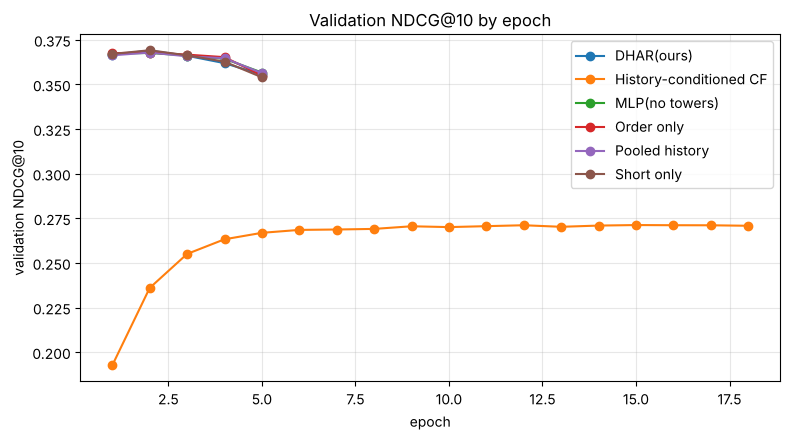

,eligible_events,unknown_events,selected_events,users_with_known_sequence,unknown_share
short,2301544,81178,337562,19569,0.035
order,785868,69835,237250,18200,0.089
cf,3091153,369011,631939,19893,0.119


In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for path in sorted(RES.glob("training_*_seed*.json")):
    log = json.loads(path.read_text(encoding="utf-8"))
    ax.plot([e["epoch"] for e in log["epochs"]], [e["val_ndcg10"] for e in log["epochs"]],
            marker="o", label=NAMES[log["variant"]])
ax.set(xlabel="epoch", ylabel="validation NDCG@10", title="Validation NDCG@10 by epoch")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

coverage = pd.DataFrame(json.loads((RES / "horizon_coverage.json").read_text(encoding="utf-8"))).T
coverage["unknown_share"] = coverage.unknown_events / coverage.eligible_events
display(coverage.round(3))

# Summary: what to say in the presentation

* **Design:** DHAR combines candidate metadata and 26 numeric features with two candidate-category-conditioned attention contexts. The NCF-style baseline instead combines a mean item-history user representation with GMF and MLP branches.
* **Protocol:** five feature-based variants and a separate CF baseline share the split, listwise loss, optimiser settings, and validation checkpoint rule. They do not all receive the same inputs.
* **Finding:** DHAR scores 0.3713 NDCG@10, compared with 0.3725 for the no-tower MLP. Added attention has no demonstrated benefit in this fixed experiment. The MLP already contains engineered history features, so this does not mean history is unimportant.
* **Verification:** B.2 recomputes NDCG@10 from saved predictions. The separate `Jiayi_Step5_Verification.ipynb` checks all 24 metrics, input-order invariance, an independent metric implementation and the paired bootstrap interval. This documentation update does not claim fresh training or checkpoint reload.

**Hand-off to Step 6:** `test_pred_neural.parquet` supplies every variant's scores. Checkpoints are produced by training but are not committed in this public checkout. Review the presentation wording and contribution statements before submission.
